# Flat metalens (10 µm aperture) — focal cone & Airy spot
A metalens focuses light with a flat, wavelength-thin structured surface instead
of a bulky curved lens. This example builds a 3-D flat lens on a glass substrate,
illuminates it with a normally-incident plane wave, and solves the full vector
Maxwell field to show the converging focal cone and the diffraction-limited Airy
spot it forms in air.

Realization: blazed surface-relief (kinoform) metalens
------------------------------------------------------
The lens imprints the hyperbolic focusing phase as a **surface-relief height
profile** of solid high-index material (TiO₂) on glass. At transverse radius r the
relief is h(r) tall, so the transmitted phase is the optical path through the
material,

    φ(r) = k₀ · (n − 1) · h(r),   wrapped so h ∈ [0, λ/(n−1)) spans a full 2π,

set to the hyperbolic lens phase φ(r) = −k₀(√(r²+f²) − f) wrapped to [0, 2π). The
result is a set of concentric blazed Fresnel zones, sub-wavelength near the rim.
Because the material is solid and fully resolved (no effective-medium model, no
isolated-pillar resonances), the phase is physically imprinted and the lens
focuses to a diffraction-limited spot.

This is a diffractive (kinoform / blazed-Fresnel) flat lens.

Why a full-wave solver is required (and ray tracing is not enough)
------------------------------------------------------------------
Image formation is pure diffraction from wavelength-scale zones, summed coherently
across the aperture: the focal cone, the Airy spot, the zone-edge scatter, and the
finite-aperture / low-Fresnel-number focal shift are all full-wave effects. A ray
tracer can model an equivalent ideal lens but not the structured surface that
physically produces the phase, so it cannot predict zone-edge scatter, the true
spot shape, or efficiency.

Domain size
-----------
The solver returns the steady-state complex field of the whole 3-D lens directly. The
default below is a 10 µm aperture; scale ``aperture`` and ``focal_length`` up for a
larger lens.

Size: 346.8 Mvoxel including boundaries, 18.09 GB of memory (service estimate).

Physics / solver mode
---------------------
Time-harmonic vector Maxwell (one CW wavelength, linear, non-magnetic). Output is
the steady-state complex vector field E = (Eₓ, E_y, E_z); intensity |E|² =
|Eₓ|²+|E_y|²+|E_z|².

Geometry (propagation = X; transverse aperture = Y, Z)
------------------------------------------------------
Along +X: air gap → glass substrate → relief layer → air focal region. The plane
wave enters through the substrate, the relief imprints the focusing phase, and the
beam converges to a focus in the air beyond. Open (absorbing) boundaries on all six
faces; the plane wave is Tukey-tapered in Y, Z so it does not diffract off the
domain edges. The source is y-polarized (transverse to the +x propagation).

Outputs (saved in output/mx_metalens/)
-------------------------------------------
  * metalens_focal_cone.png   — X–Y cut (z = centre): the plane wave hits
    the flat relief and converges into a focal cone in air;
  * metalens_airy_spot.png    — transverse |E|² at the focal plane (the
    Airy spot) plus a 1-D cut with the measured FWHM vs the diffraction limit.

Both figures are cross-sections, so by default the run uses two monitors (an axial
X–Y slab and a transverse Y–Z slab at the focus) and the cloud returns only those
planes; set ``USE_MONITOR = False`` to fetch the full volume instead (identical
figures). The substrate + blazed relief are NumPy.

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

from wsutils import apodise, output_dir
from wavesimpro import configure, simulate, create_monitor

NAME = "mx_metalens"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME)

### Parameters

In [2]:
wavelength = 0.532  # Wavelength in micrometer (μm) — green light, in the air background

pixel_size = 0.03  # Grid spacing in μm (~λ/17.7 in air; resolves the relief, ~13 voxels tall,
#                    and the sub-λ zones near the rim). Use 0.04 for a coarser grid.

# Materials.
n_lens = 2.4       # TiO₂-like relief index at visible wavelengths (real, low-loss)
n_substrate = 1.5  # glass substrate
n_bg = 1.0         # air (background and focal medium)

# Metalens aperture & focusing; scale both up for a larger lens.
aperture = 10.0       # diameter of the circular aperture, μm
focal_length = 12.0   # design focal length from the relief exit plane, μm

# −1 is the focusing sign (standard convention): a converging phase collapses to a
# focus a distance f beyond the lens; +1 would diverge.
focusing_sign = -1.0

k0 = 2 * np.pi / wavelength
max_height = wavelength / (n_lens - 1)  # relief height spanning a full 2π, μm

NA = (aperture / 2) / np.sqrt((aperture / 2) ** 2 + focal_length ** 2)  # numerical aperture
dl_fwhm = 0.51 * wavelength / NA  # diffraction-limited focal-spot FWHM, μm

# Domain layout along X (propagation): air gap → substrate → relief → air focus.
x_src = 0.6        # plane-wave launch X, μm (in the air gap, after the absorbing boundary)
x_sub0 = 1.0       # substrate front face, μm
t_substrate = 1.5  # substrate thickness, μm
x_relief0 = x_sub0 + t_substrate         # relief base (on the substrate), μm
x_relief1 = x_relief0 + max_height        # tallest the relief can be, μm
x_focus = x_relief1 + focal_length        # design focus depth, μm
x_end = x_focus + 3.0                      # a little air beyond the focus, μm

# Transverse extent: aperture plus margin so the converging cone clears the walls.
transverse = aperture + 5.0  # μm (Y and Z)

sim_size = np.array([x_end, transverse, transverse])  # (x, y, z) μm
n_size = (sim_size / pixel_size).astype(int)
nx, ny, nz = (int(v) for v in n_size)
cy = cz = transverse / 2  # optical axis (Y, Z centre), μm

taper = 0.3  # Tukey taper fraction for the plane wave in Y, Z (zeros the edges)

print(f"Domain {sim_size} μm = {nx}x{ny}x{nz} voxels ({nx * ny * nz / 1e6:.1f} Mvoxel without boundaries)")
print(f"Metalens: aperture {aperture} μm, f = {focal_length} μm, NA = {NA:.2f}")
print(f"Relief: n={n_lens}, height 0…{max_height:.3f} μm (~{max_height / pixel_size:.0f} voxels, full 2π)")
print(f"Diffraction-limited spot FWHM ≈ 0.51 λ/NA ≈ {dl_fwhm:.2f} μm; focus at x ≈ {x_focus:.1f} μm")

Domain [17.88 15.   15.  ] μm = 596x500x500 voxels (149.0 Mvoxel without boundaries)
Metalens: aperture 10.0 μm, f = 12.0 μm, NA = 0.38
Relief: n=2.4, height 0…0.380 μm (~13 voxels, full 2π)
Diffraction-limited spot FWHM ≈ 0.51 λ/NA ≈ 0.71 μm; focus at x ≈ 14.9 μm


### Medium: substrate + blazed surface-relief lens (concentric zones)

In [3]:
def build_metalens():
    """Rasterize the substrate + radial blazed relief into an (nx, ny, nz) permittivity grid."""
    n = np.full((nx, ny, nz), n_bg, dtype=np.complex64)
    x = np.arange(nx) * pixel_size
    y = np.arange(ny) * pixel_size
    z = np.arange(nz) * pixel_size

    # Glass substrate slab (full transverse extent).
    n[(x >= x_sub0) & (x < x_relief0), :, :] = n_substrate

    # Radial relief height from the wrapped hyperbolic focusing phase.
    R, Z = np.meshgrid(y - cy, z - cz, indexing="ij")  # (ny, nz)
    r = np.sqrt(R ** 2 + Z ** 2)
    in_ap = r <= aperture / 2
    phase = np.mod(focusing_sign * k0 * (np.sqrt(r ** 2 + focal_length ** 2) - focal_length),
                   2 * np.pi)
    h = phase / (k0 * (n_lens - 1))  # height per (y, z) column, μm
    h[~in_ap] = 0.0
    ih = np.round(h / pixel_size).astype(int)  # height in voxels

    # Paint each column up to its height (vectorized over the relief layer thickness).
    ix0 = int(x_relief0 / pixel_size)
    n_layers = int(np.ceil(max_height / pixel_size)) + 1
    for k in range(n_layers):
        mask = ih > k  # columns tall enough to include this layer
        n[ix0 + k, mask] = n_lens

    print(f"Relief built across the {aperture} μm aperture "
          f"(height range {h[in_ap].min():.3f}…{h[in_ap].max():.3f} μm, "
          f"{int(in_ap.sum())} columns)")
    return (n ** 2).astype(np.complex64)


permittivity = build_metalens()

Relief built across the 10.0 μm aperture (height range 0.000…0.380 μm, 87253 columns)


### Source: apodized normally-incident plane wave (y-polarized, vector)

In [4]:
# A yz sheet at x_src, Tukey-tapered (→ exactly 0 at the absorbing walls). Axis
# order is (polarization, x, y, z): a yz sheet at one x-plane is (1, 1, ny, nz).
# position[0]=1 ⇒ y-polarization (transverse to the +x propagation).
source_values = np.ones((1, 1, ny, nz), dtype=np.complex64)
source_position = (1, int(x_src / pixel_size), 0, 0)  # (polarization=y, x, y, z) in pixels
source_values, source_position = apodise((source_values, source_position),
                                         axes="yz", alpha=taper)

iy_c, iz_c = ny // 2, nz // 2  # optical axis (Y, Z centre) in voxels

### Monitors (recommended): the two cross-sections the figures use

In [5]:
# Both figures are cross-sections, so two thin monitor slabs capture everything the
# cloud needs to return — identical figures, a fraction of the data. Set
# USE_MONITOR = False to fetch the full volume instead. A voxel index i on an
# n-voxel axis sits at (i + 0.5 - n/2)*px in domain-centred world coordinates.
#   * "axial": X–Y slab at z = cz (full x, y; thin z) -> focal cone + on-axis focus
#   * "focal": Y–Z slab at the design focus (full y, z; thin x) -> Airy spot. The
#     depth of focus (~lambda/(2 NA^2)) dwarfs any finite-aperture focal shift, so
#     the focus lands inside this band and the argmax below picks its peak plane.
USE_MONITOR = True
if USE_MONITOR:
    z_world = (iz_c + 0.5 - nz / 2) * pixel_size
    ix_focus_design = int(round(x_focus / pixel_size))
    x_world = (ix_focus_design + 0.5 - nx / 2) * pixel_size
    monitor_list = [
        create_monitor(name="axial", center_x=0.0, center_y=0.0, center_z=z_world,
                       size_x=nx * pixel_size, size_y=ny * pixel_size, size_z=3 * pixel_size),
        create_monitor(name="focal", center_x=x_world, center_y=0.0, center_z=0.0,
                       size_x=10 * pixel_size, size_y=ny * pixel_size, size_z=nz * pixel_size),
    ]
else:
    monitor_list = None

### Solve

In [6]:
print("\nRunning simulation...")
start = time()
u, iterations, residual_norm = simulate(
    permittivity=permittivity,
    sources=[(source_values, source_position)],
    wavelength=wavelength,
    pixel_size=pixel_size,
    boundary_width=2.5,  # absorbing boundary width, μm (≈5 λ), open on all six faces
    periodic=(False, False, False),
    monitors=monitor_list,
)
print(f"Time {time() - start:.1f} s; Iterations {iterations}; Residual {residual_norm:.2e}")


Running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : cb1d63b7-8c60-4013-ad31-1da2488295c6
  Version   : f429b628-bfe3-4cad-b86d-ba3ee6bb831c
  Command   : 9bccf9eb-5269-445c-a845-a7d1e59e525a
  Mode      : Maxwell (vectorial)
  Domain    : 596x500x500 voxels  lambda=0.532 um  dx=0.030 um
  Engine    : Any (auto-select)  |  GPU: CPU
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 2685.1 s; Iterations 984; Residual 9.99e-07


### Reduce to the cross-sections the figures need

In [7]:
# Either index the two monitor fields, or slice the equivalent planes from the full
# volume. Both paths produce the same arrays: the axial amplitude plane `sl`, the
# on-axis intensity vs x `axis_band`, and the transverse focal-plane intensity.
ix_air0 = int((x_relief1 + 0.5) / pixel_size)  # search only in the air focal region
if USE_MONITOR:
    int_axial = (np.abs(u[0]) ** 2).sum(axis=0)   # (nx, ny, mz) from the "axial" slab
    jz = int_axial.shape[2] // 2                   # mid of the z-slab = optical axis
    sl = np.sqrt(int_axial[:, :, jz])              # (nx, ny) amplitude, == amp[:, :, iz_c]
    axis_band = int_axial[:, iy_c - 1:iy_c + 2, jz - 1:jz + 2].mean(axis=(1, 2))
    int_focal = (np.abs(u[1]) ** 2).sum(axis=0)    # (mx, ny, nz) from the "focal" slab
    jf = int(np.argmax(int_focal[:, iy_c, iz_c]))  # peak on-axis plane within the slab
    focal_plane = int_focal[jf, :, :]              # (ny, nz)
else:
    u = np.asarray(u)  # vector field (3, nx, ny, nz), host NumPy
    intensity = (np.abs(u) ** 2).sum(axis=0)  # |E|² = |Ex|²+|Ey|²+|Ez|², (nx, ny, nz)
    amp = np.sqrt(intensity)
    sl = amp[:, :, iz_c]
    axis_band = intensity[:, iy_c - 1:iy_c + 2, iz_c - 1:iz_c + 2].mean(axis=(1, 2))

### Locate the actual focus (on-axis intensity in the air region)

In [8]:
ix_focus = ix_air0 + int(np.argmax(axis_band[ix_air0:]))
x_focus_meas = ix_focus * pixel_size
if not USE_MONITOR:
    focal_plane = intensity[ix_focus, :, :]  # (ny, nz)
print(f"\nMeasured focus at x = {x_focus_meas:.2f} μm (design {x_focus:.2f} μm)")


Measured focus at x = 14.07 μm (design 14.88 μm)


### Figure 1: X–Y focal cone (z = centre)

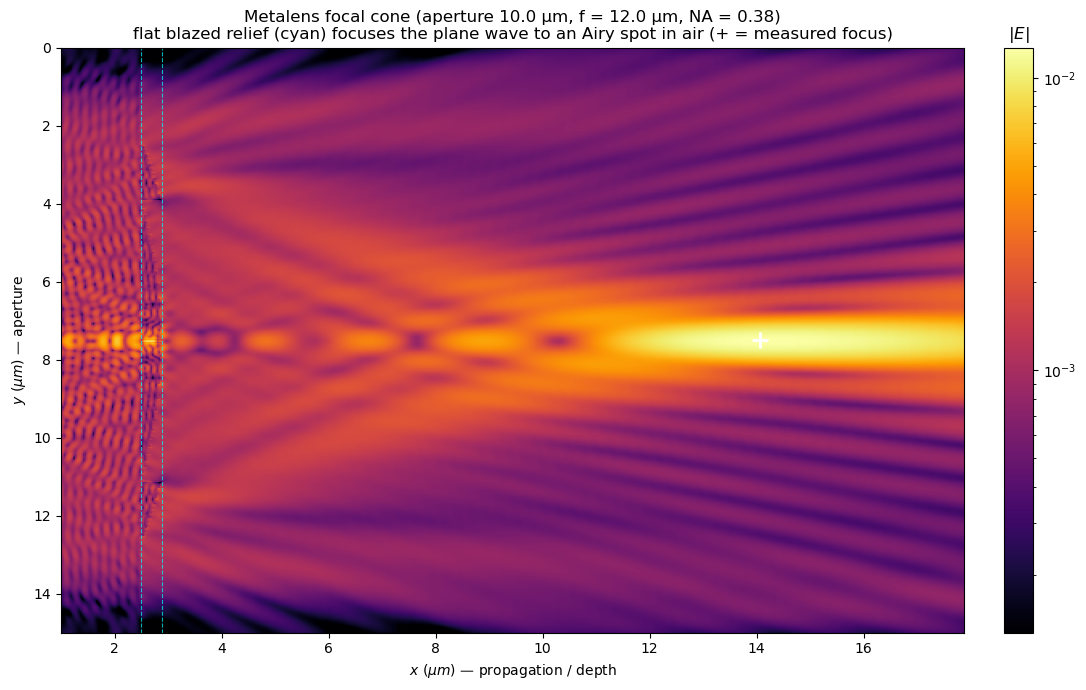

In [9]:
vmax = sl.max()
vmin = vmax * 1e-2  # two decades pops the cone over the substrate standing-wave ripple
extent = [0, nx * pixel_size, ny * pixel_size, 0]  # x horizontal, y vertical (origin top)

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(sl.T, cmap="inferno", extent=extent,
               norm=colors.LogNorm(vmin=vmin, vmax=vmax), aspect="auto")
ax.axvline(x_relief0, color="cyan", lw=0.8, ls="--", alpha=0.7)
ax.axvline(x_relief1, color="cyan", lw=0.8, ls="--", alpha=0.7)
ax.plot(x_focus_meas, cy, "+", color="white", ms=12, mew=2)
ax.set_xlim(x_sub0, nx * pixel_size)
ax.set_xlabel(r"$x~(\mu m)$ — propagation / depth")
ax.set_ylabel(r"$y~(\mu m)$ — aperture")
ax.set_title(f"Metalens focal cone (aperture {aperture} μm, f = {focal_length} μm, NA = {NA:.2f})\n"
             "flat blazed relief (cyan) focuses the plane wave to an Airy spot in air "
             "(+ = measured focus)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.set_title(r"$|E|$")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/metalens_focal_cone.png", dpi=300, bbox_inches="tight")

### Figure 2: transverse Airy spot at the focal plane + FWHM cut

Focal-spot FWHM: measured 720 nm vs diffraction limit 705 nm (0.51 λ/NA)
Saved output/mx_metalens/metalens_focal_cone.png and output/mx_metalens/metalens_airy_spot.png


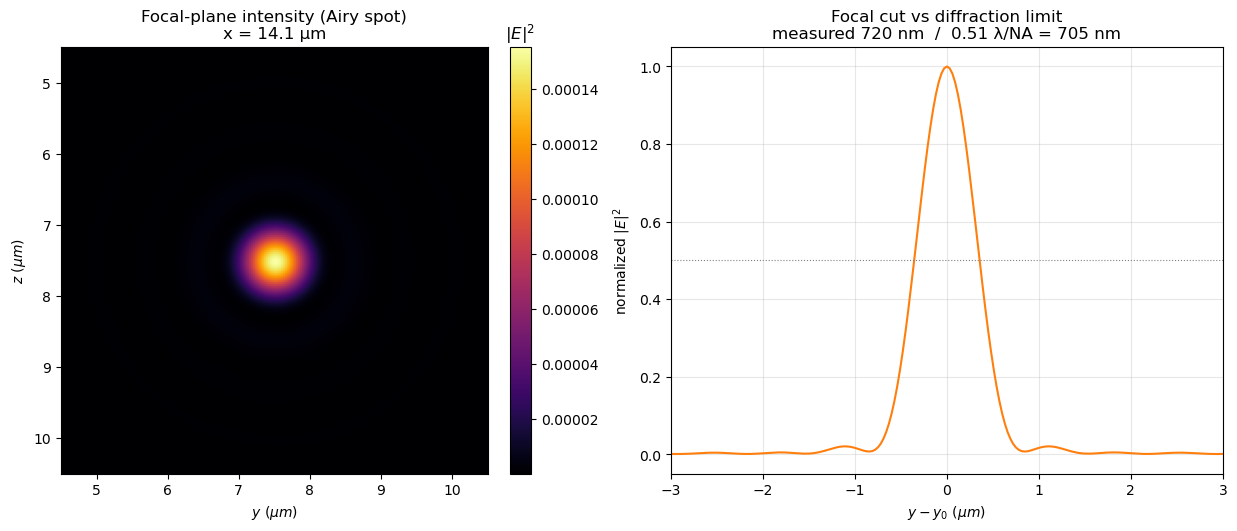

In [10]:
y = np.arange(ny) * pixel_size
cut = focal_plane[:, iz_c]  # 1-D cut through the focus along Y
cut_n = cut / cut.max()

# FWHM of the central lobe by the half-max crossings nearest the peak.
iy_pk = int(np.argmax(cut_n))
left = np.where(cut_n[:iy_pk] <= 0.5)[0]
right = np.where(cut_n[iy_pk:] <= 0.5)[0]
if len(left) and len(right):
    fwhm = (right[0] + iy_pk - left[-1]) * pixel_size
else:
    fwhm = float("nan")

extent_t = [0, ny * pixel_size, nz * pixel_size, 0]
fig2, (axa, axb) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

imf = axa.imshow(focal_plane.T, cmap="inferno", extent=extent_t, aspect="equal")
axa.set_title(f"Focal-plane intensity (Airy spot)\nx = {x_focus_meas:.1f} μm")
axa.set_xlabel(r"$y~(\mu m)$")
axa.set_ylabel(r"$z~(\mu m)$")
axa.set_xlim(cy - 3, cy + 3)
axa.set_ylim(cz + 3, cz - 3)
fig2.colorbar(imf, ax=axa, fraction=0.046, pad=0.04).ax.set_title(r"$|E|^2$")

axb.plot(y - cy, cut_n, "-", color="tab:orange", lw=1.5)
axb.axhline(0.5, color="grey", ls=":", lw=0.8)
axb.set_xlim(-3, 3)
axb.set_xlabel(r"$y - y_0~(\mu m)$")
axb.set_ylabel(r"normalized $|E|^2$")
axb.set_title(f"Focal cut vs diffraction limit\n"
              f"measured {fwhm * 1000:.0f} nm  /  0.51 λ/NA = {dl_fwhm * 1000:.0f} nm")
axb.grid(True, alpha=0.3)
fig2.savefig(f"{OUTPUT_DIR}/metalens_airy_spot.png", dpi=300, bbox_inches="tight")

print(f"Focal-spot FWHM: measured {fwhm * 1000:.0f} nm vs diffraction limit "
      f"{dl_fwhm * 1000:.0f} nm (0.51 λ/NA)")
print(f"Saved output/{NAME}/metalens_focal_cone.png and output/{NAME}/metalens_airy_spot.png")

plt.show()